# Prefix-Cache Invalidation Benchmark — Analysis Notebook

Run on **Qwen/Qwen2.5-14B-Instruct** with **RTX PRO 6000 Blackwell Server Edition**, vLLM 0.34.0, prefix caching enabled (block size 16).

Summary of methodology and artifacts.

In [1]:
from pathlib import Path
import json

ART = Path("artifacts/vm_results/results")
summary = json.loads((ART / "summary_metrics.json").read_text())
telemetry = json.loads((ART / "server_telemetry.json").read_text())

print("model:", summary["config"]["vllm_server"]["model"])
print("gpu:", telemetry["gpu_start"]["name"])
print("vllm:", telemetry["versions"]["vllm"], "torch:", telemetry["versions"]["torch"])
print("measured requests:", summary["run"]["measured_requests"])


model: Qwen/Qwen2.5-14B-Instruct
gpu: NVIDIA RTX PRO 6000 Blackwell Server Edition
vllm: 0.34.0 torch: 2.14.0
measured requests: 150


## Arms and protocol

In [2]:
cfg = summary["config"]["benchmark"]
print("scenarios x reps:", cfg["num_scenarios"], "x", cfg["trials_per_scenario"])
print("concurrency/temperature/max_tokens:", cfg["concurrency"], cfg["temperature"], cfg["max_tokens"])
print("prefix_target_tokens:", cfg["prefix_target_tokens"])
print("tool_output_target_tokens:", cfg["tool_output_target_tokens"])
print("token_parity_tolerance:", cfg["token_parity_tolerance"])
print("shorter_ratio band:", cfg["shorter_prompt_min_ratio"], "-", cfg["shorter_prompt_max_ratio"])


scenarios x reps: 10 x 5
concurrency/temperature/max_tokens: 1 0.0 512
prefix_target_tokens: 5500
tool_output_target_tokens: 2200
token_parity_tolerance: 2
shorter_ratio band: 0.65 - 0.75


## Per-arm results

In [3]:
from IPython.display import HTML

rows = []
for arm in ("append_only", "rewrite_equal_tokens", "rewrite_shorter_prompt"):
    m = summary["arms"][arm]["metrics"]
    acc = summary["arms"][arm]["accuracy"]["accuracy_pct"]
    rows.append([
        arm,
        round(m["total_input_tokens"]["mean"], 1),
        round(m["cached_input_tokens_usage"]["mean"], 1),
        round(m["uncached_input_tokens_usage"]["mean"], 1),
        round(m["ttft_ms"]["mean"], 2),
        round(m["e2e_ms"]["mean"], 2),
        round(m["itl_ms"]["mean"], 3),
        round(m["completion_tokens"]["mean"], 1),
        acc,
    ])

HTML(
    "<table><thead><tr><th>arm</th><th>total</th><th>cached</th><th>uncached</th>"
    "<th>TTFT ms</th><th>E2E ms</th><th>ITL ms</th><th>compl. tok</th><th>acc</th></tr></thead>"
    "<tbody>" + "".join("<tr>" + "".join(f"<td>{c}</td>" for c in r) + "</tr>" for r in rows) + "</tbody></table>"
)

arm,total,cached,uncached,TTFT ms,E2E ms,ITL ms,compl. tok,acc
append_only,7761.6,5488.0,2273.6,40.12,369.24,2.303,142.8,84.0
rewrite_equal_tokens,7761.6,212.8,7548.8,68.04,359.75,2.286,127.3,74.0
rewrite_shorter_prompt,5433.1,213.8,5219.3,43.89,381.71,2.136,158.9,80.0


## Paired deltas, break-even, and regression

In [4]:
pairs = summary["paired"]
reg = summary["derived"]["regression_ttft_vs_uncached"]
br = summary["derived"]["break_even"]

for name in ("rewrite_equal_tokens_vs_append_only", "rewrite_shorter_prompt_vs_append_only"):
    m = pairs[name]["metrics"]
    print(name)
    print("  uncached delta mean:", round(m["uncached_input_tokens_usage"]["delta"]["mean"], 2))
    print("  TTFT delta mean:", round(m["ttft_ms"]["delta"]["mean"], 3), "ms")
    print("  TTFT delta 95% CI:", [round(x, 3) for x in m["ttft_ms"]["delta_mean_95ci"]])
    print("  ratio to A:", round(m["ttft_ms"]["delta"]["mean"] / summary["arms"]["append_only"]["metrics"]["ttft_ms"]["mean"], 4))

print("regression: TTFT ≈ %.3f + %.6f * uncached_tokens" % (reg["intercept_ms"], reg["slope_ms_per_1k_uncached_tokens"] / 1000))
print("  R^2:", round(reg["r2"], 4))
print("break-even total ratio:", br["ratio_of_A_total"])
print("break-even absolute tokens:", br["absolute_total_tokens"])


rewrite_equal_tokens_vs_append_only
  uncached delta mean: 5275.2
  TTFT delta mean: 27.914 ms
  TTFT delta 95% CI: [27.197, 28.551]
  ratio to A: 0.6957
rewrite_shorter_prompt_vs_append_only
  uncached delta mean: 2945.74
  TTFT delta mean: 3.764 ms
  TTFT delta 95% CI: [3.098, 4.305]
  ratio to A: 0.0938
regression: TTFT ≈ 25.021 + 0.005118 * uncached_tokens
  R^2: 0.7727
break-even total ratio: 0.32040816326530613
break-even absolute tokens: 2486.88


## Charts

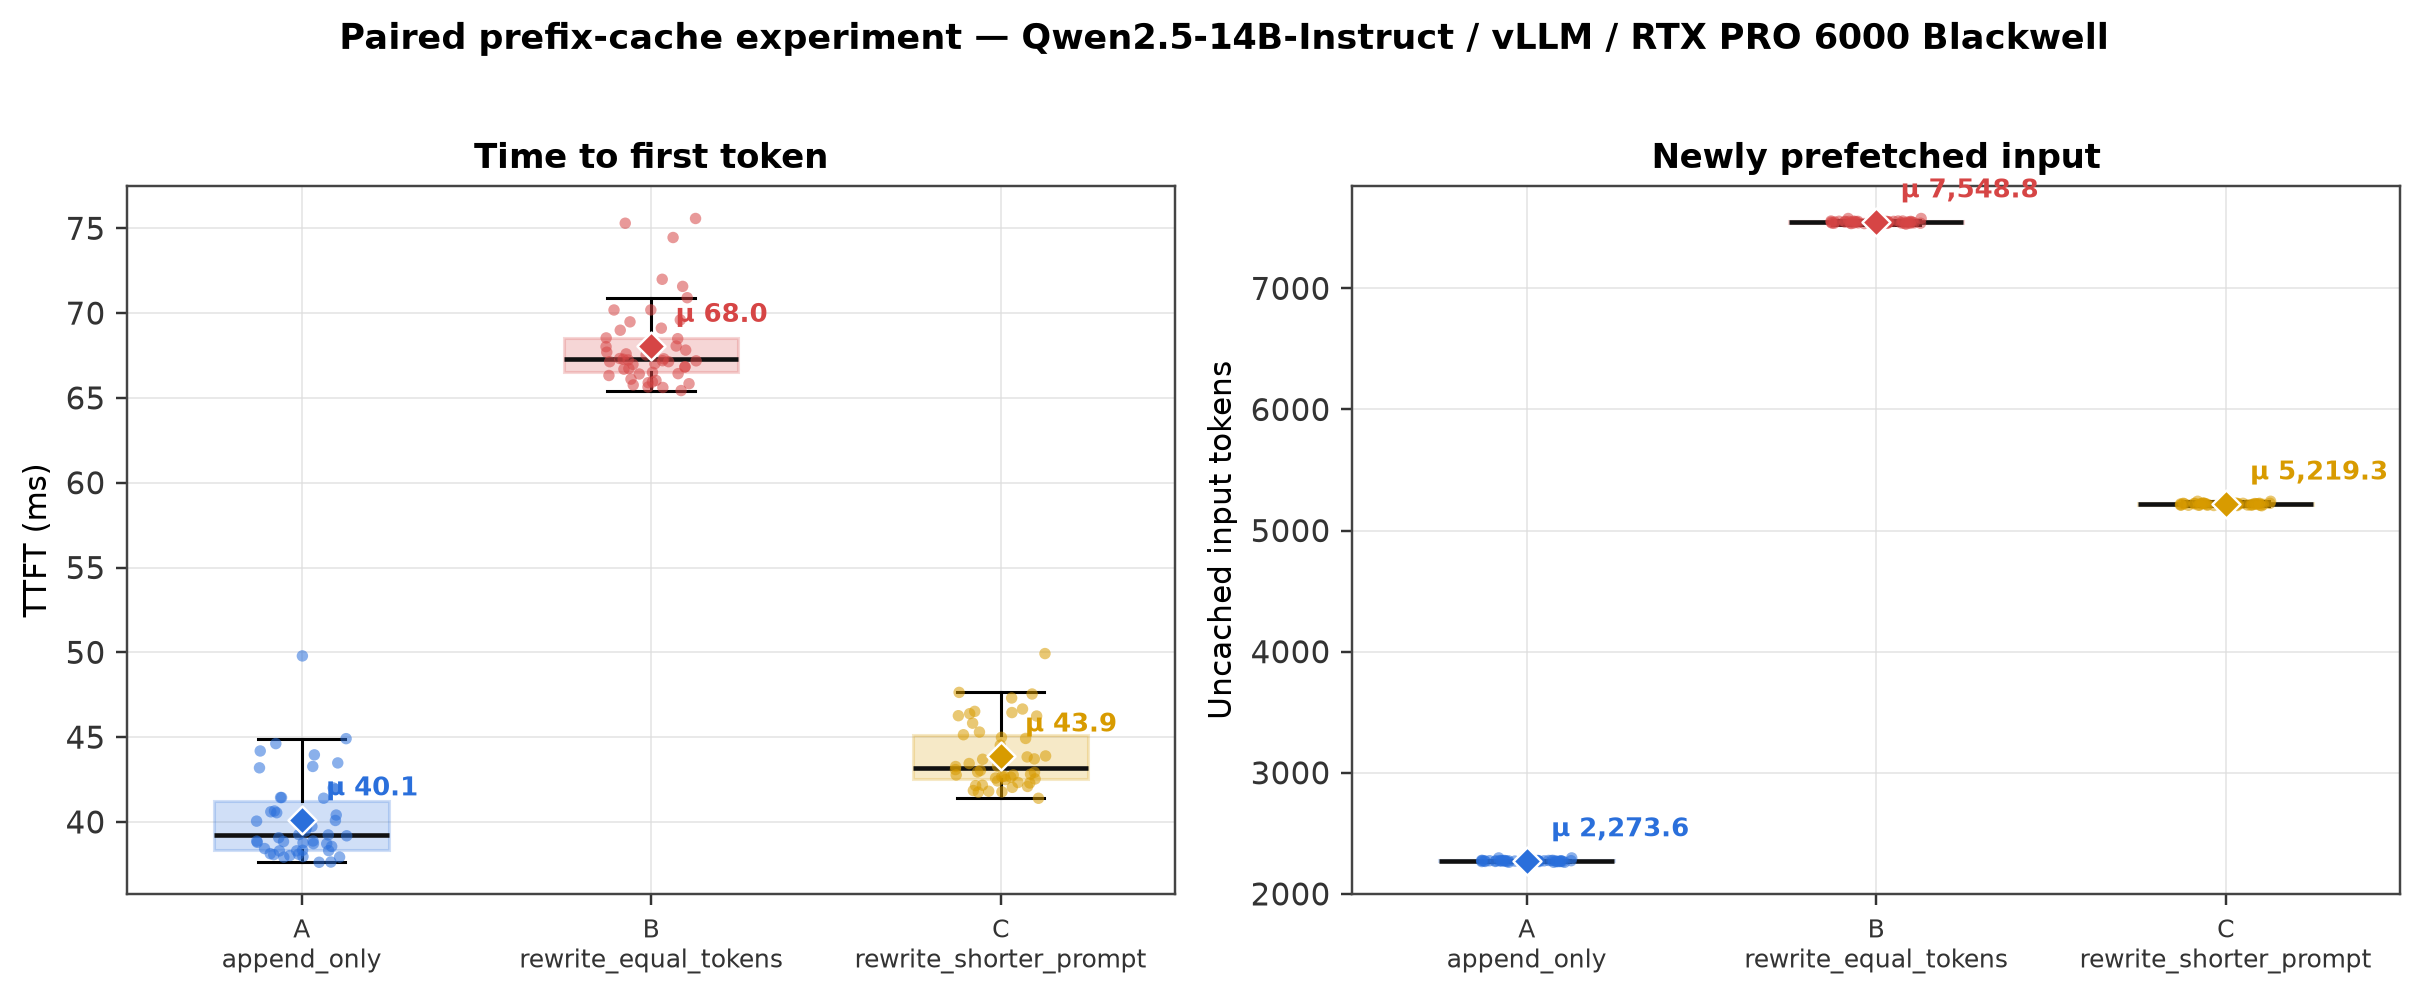

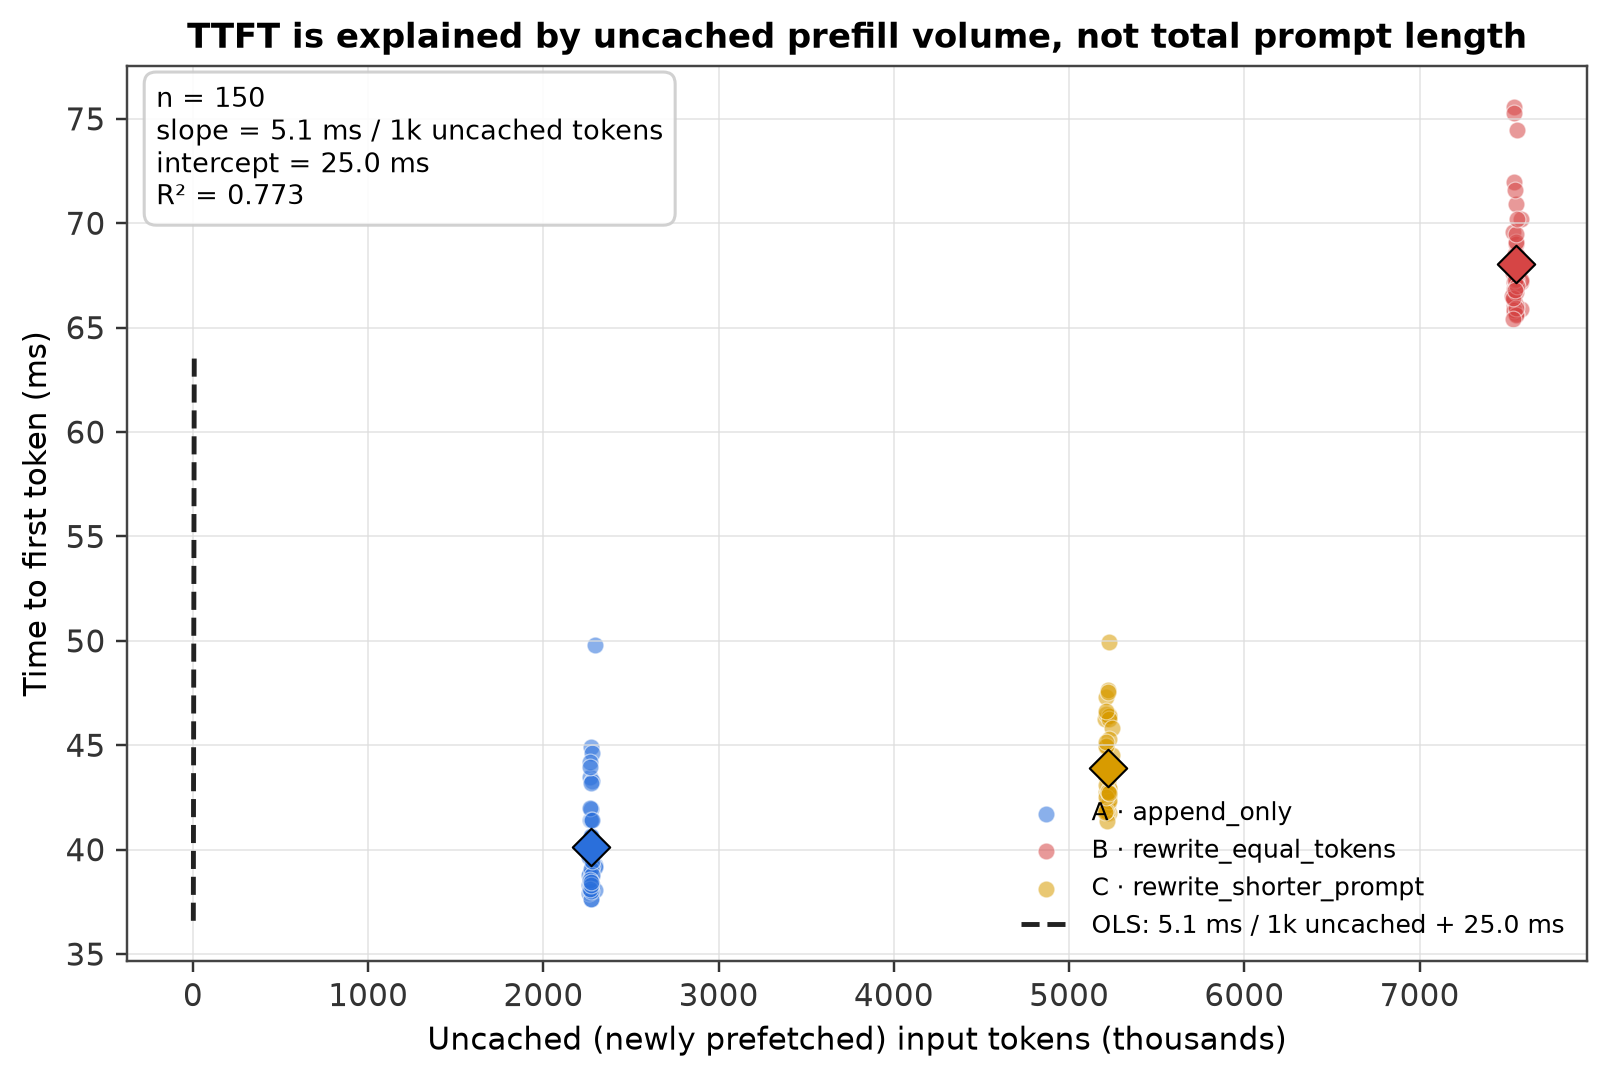

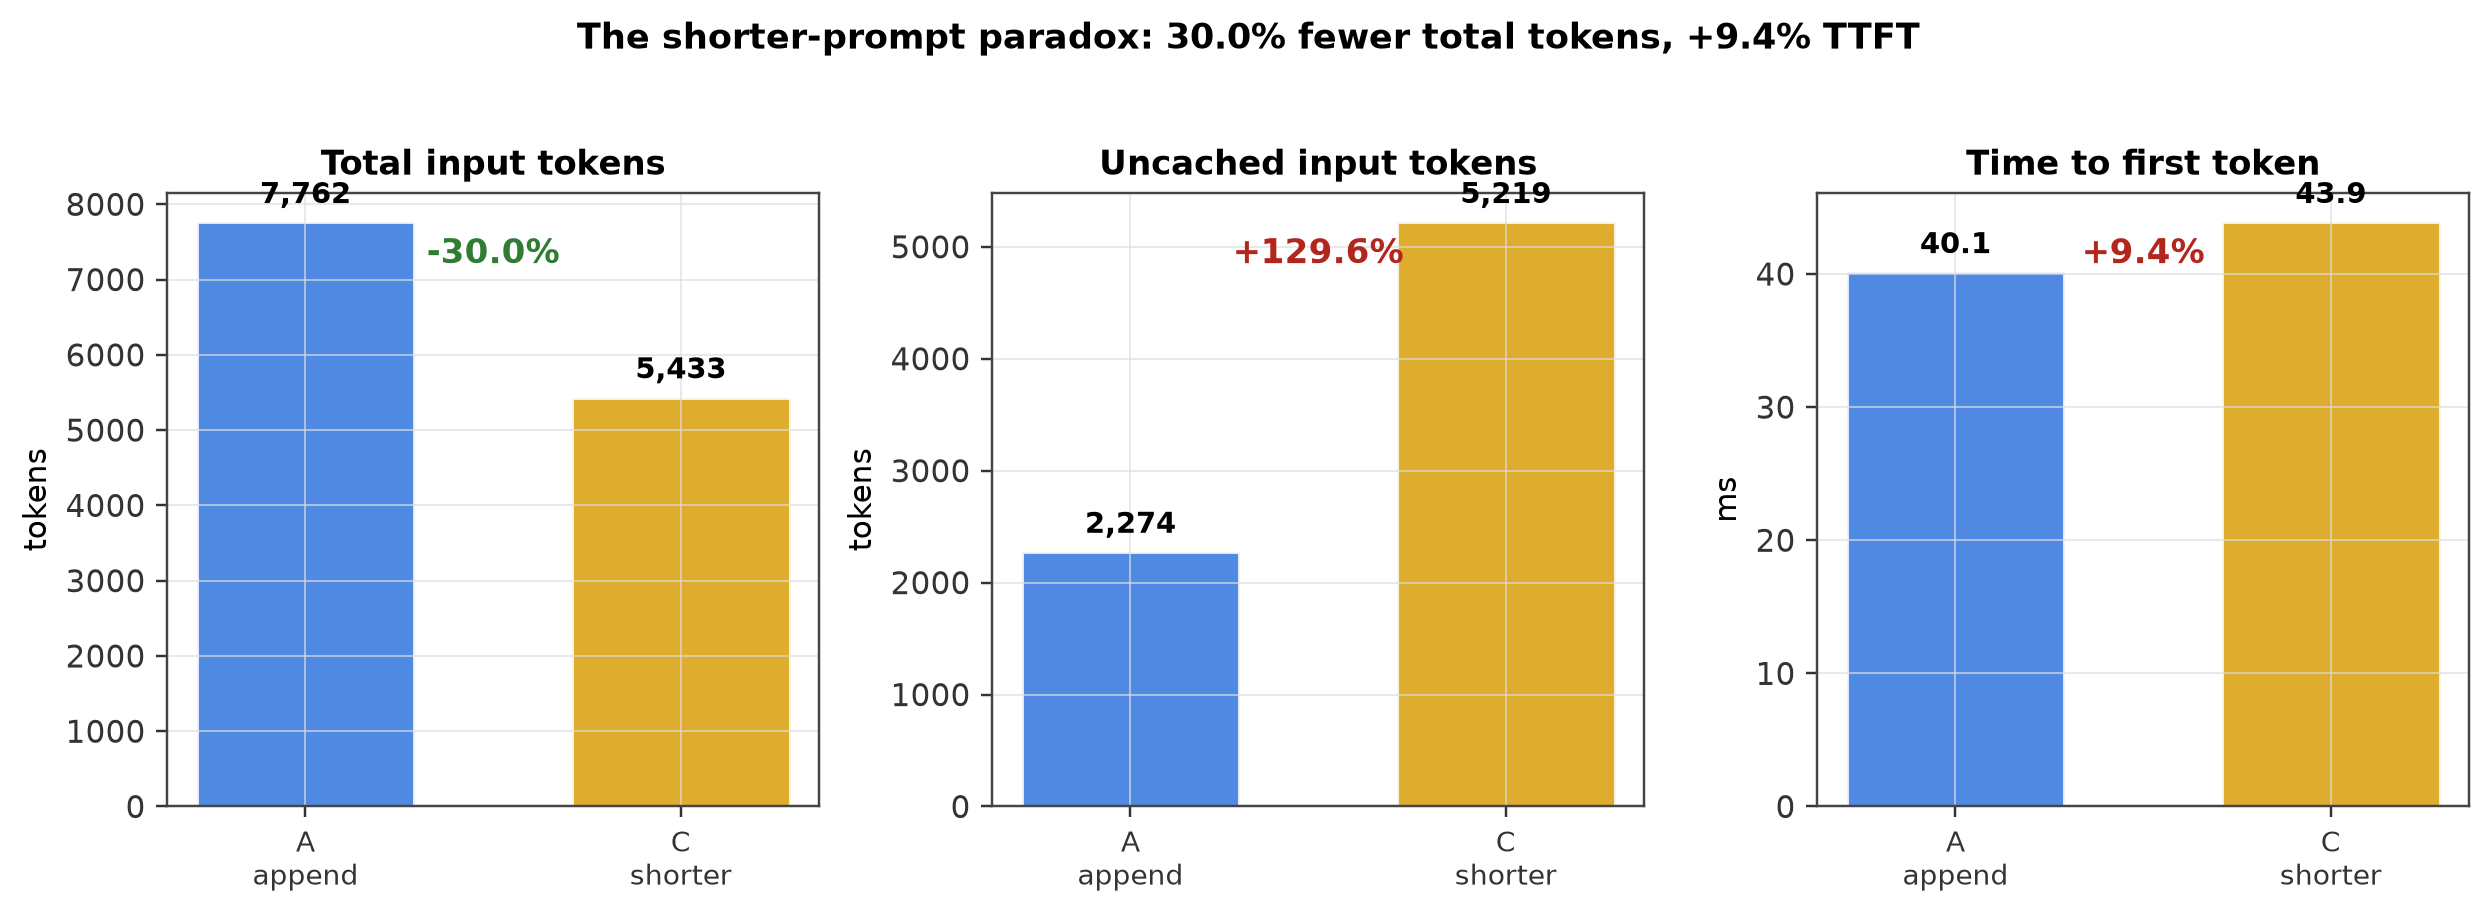

In [5]:
from IPython.display import Image, display
for p in (ART / "ttft_comparison.png", ART / "uncached_tokens_vs_ttft.png", ART / "shorter_prompt_paradox.png"):
    display(Image(filename=p, width=640))


## Raw artifacts and reproduction

In [6]:
print((ART / "raw_trials.jsonl").resolve())
print((ART / "summary_metrics.json").resolve())


/Users/mozart/Documents/ml/cache_test/artifacts/vm_results/results/raw_trials.jsonl
/Users/mozart/Documents/ml/cache_test/artifacts/vm_results/results/summary_metrics.json


In [7]:
# Reproduce on the VM/ anywhere:HF_HOME=/home/ubuntu/hf python benchmark_prefix_vs_rewrite.py --config run.yaml


## Additional charts and diagrams

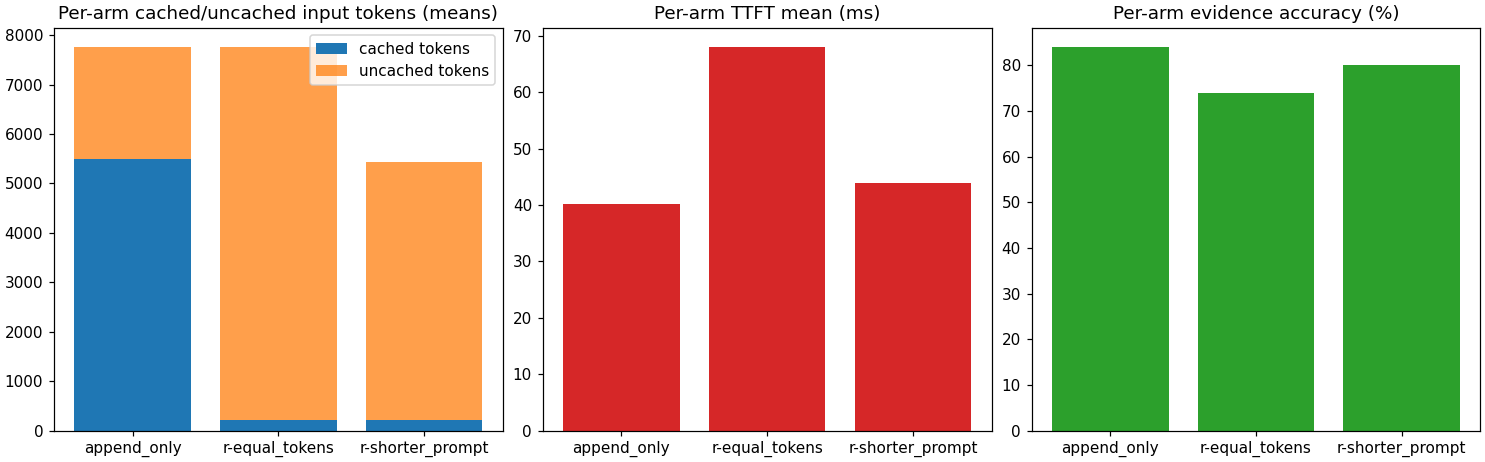

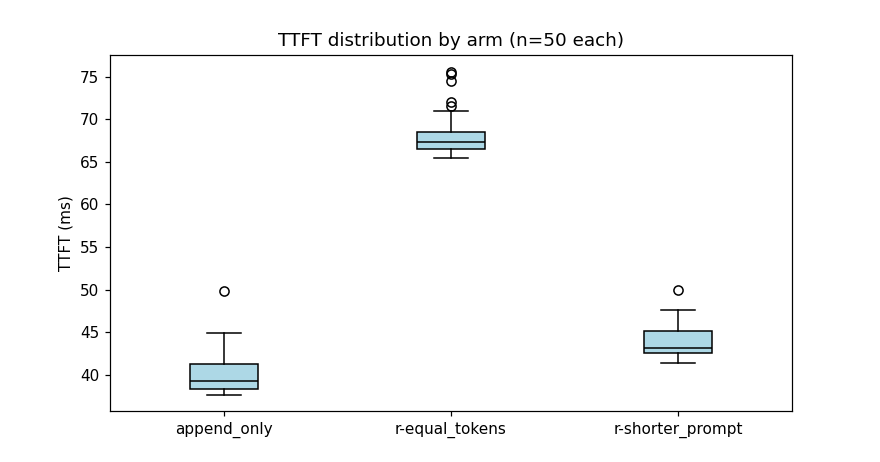

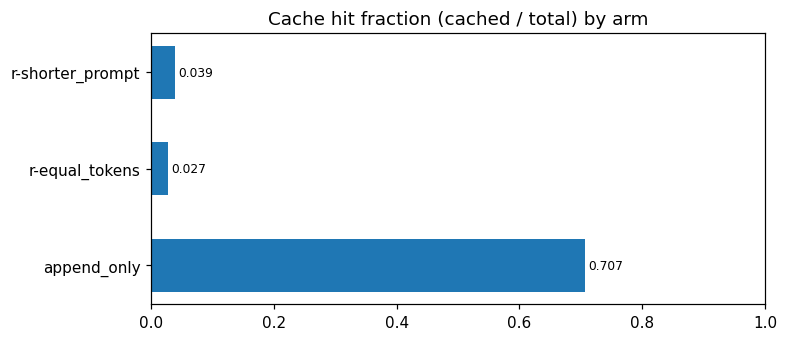

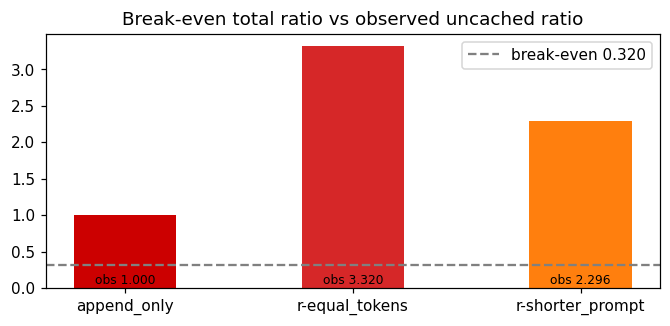

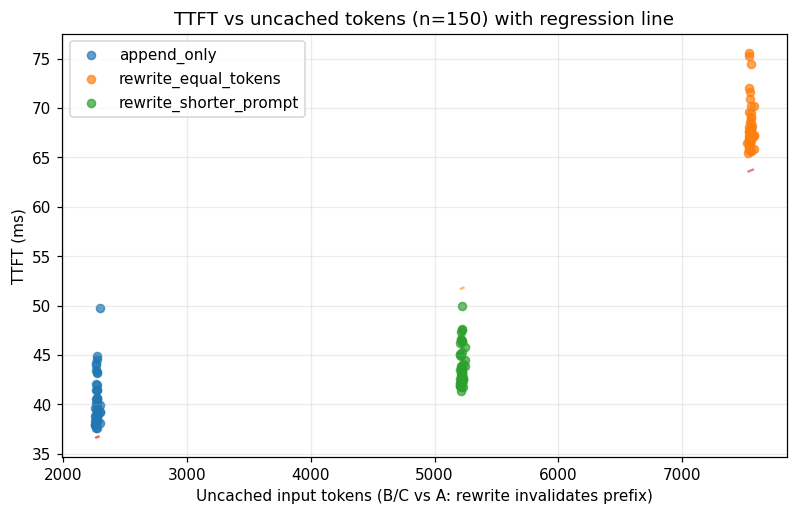

In [8]:
from IPython.display import Image, display
for p in (ART / "arm_metrics_bars.png", ART / "ttft_boxplot_by_arm.png", ART / "cached_fraction_bars.png", ART / "break_even_vs_observed.png", ART / "uncached_vs_ttft_scatter.png"):
    display(Image(filename=p, width=680))

## Protocol diagram

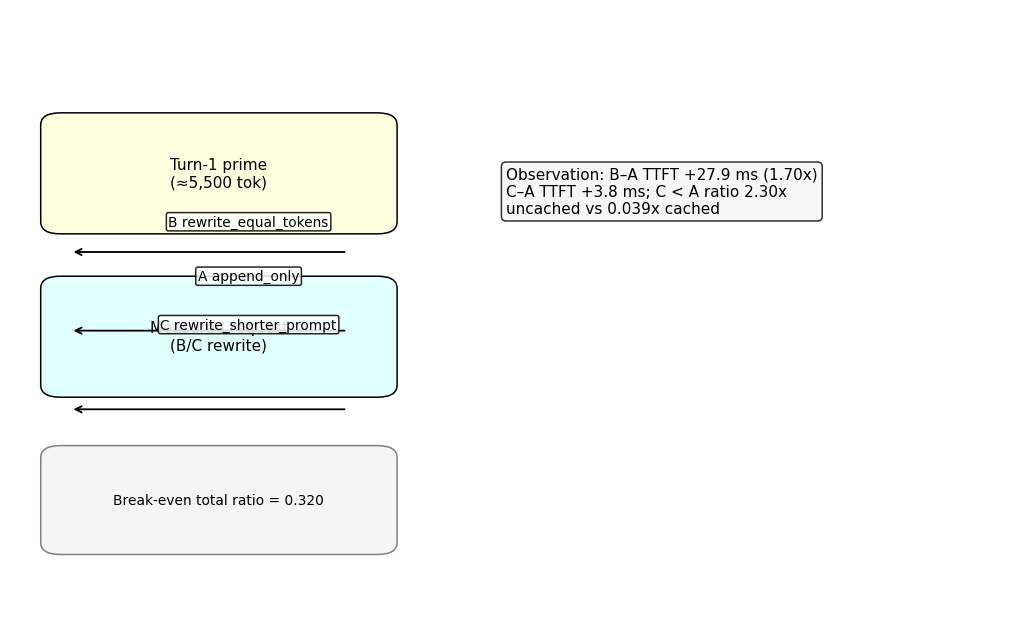

In [9]:
display(Image(filename=ART / "protocol_diagram.png", width=720))